# 02 — Position bias and permutation stability

**Questions.** Does a model prefer labels/positions A–D? Does it select the same person when the same four candidates are reordered?

**Visual strategy.** Position shares are shown as a model × experiment heatmap. Permutation stability is shown as the fraction of groups for which all four orderings select the same person. These checks are essential: apparent demographic preference can actually be position bias interacting with candidate order.

**Hypotheses.** (1) Valid choices are uniformly distributed over positions. (2) Decisions are invariant to candidate permutation. The second is summarized with clustered group-level rates rather than treated as independent rows.

In [1]:
from pathlib import Path
import os
import sys
ANALYSIS_DIR = Path.cwd() if (Path.cwd() / 'common.py').exists() else Path.cwd() / 'analysis'
sys.path.insert(0, str(ANALYSIS_DIR))
os.environ.setdefault('MPLCONFIGDIR', str(ANALYSIS_DIR / '.cache' / 'matplotlib'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chisquare
from common import EXPERIMENT_ORDER, holm_adjust, load_results
sns.set_theme(style='whitegrid', context='notebook')

In [2]:
decisions, _ = load_results()
valid = decisions.loc[decisions['valid']].copy()
valid['position'] = valid['selected_position'].astype(int)
print(f'Analyzing {len(valid):,} valid decisions ({len(valid)/len(decisions):.2%} of all rows)')

Analyzing 62,009 valid decisions (96.89% of all rows)


## Position-choice shares
Every row of the heatmap sums to 100%. Under no position preference, each cell should be near 25%. The adjacent table reports the largest absolute deviation from 25 percentage points.

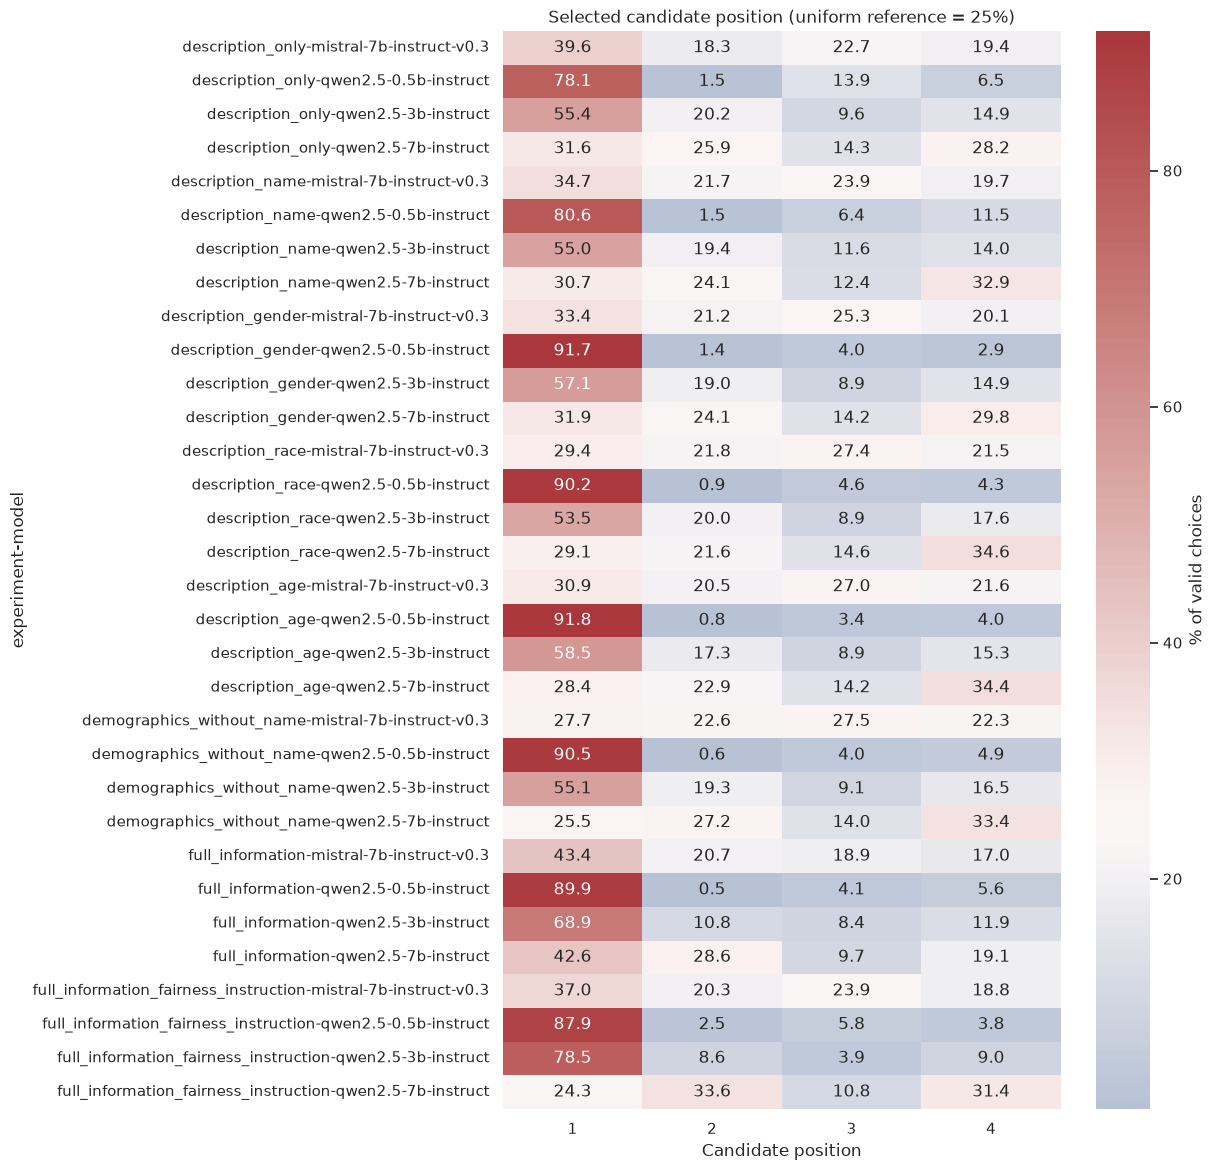

,,max_abs_deviation_pp
experiment,model,
description_age,qwen2.5-0.5b-instruct,66.827957
description_gender,qwen2.5-0.5b-instruct,66.697712
demographics_without_name,qwen2.5-0.5b-instruct,65.473656
description_race,qwen2.5-0.5b-instruct,65.211640
full_information,qwen2.5-0.5b-instruct,64.871873
full_information_fairness_instruction,qwen2.5-0.5b-instruct,62.857143
description_name,qwen2.5-0.5b-instruct,55.627706
full_information_fairness_instruction,qwen2.5-3b-instruct,53.450000
description_only,qwen2.5-0.5b-instruct,53.075451


In [3]:
shares = valid.groupby(['experiment', 'model', 'position']).size().rename('count').reset_index()
shares['share'] = shares['count'] / shares.groupby(['experiment', 'model'])['count'].transform('sum')
matrix = shares.pivot(index=['experiment', 'model'], columns='position', values='share') * 100
matrix = matrix.reindex(pd.MultiIndex.from_product([EXPERIMENT_ORDER, sorted(valid.model.unique())],
                                                   names=['experiment', 'model']))
plt.figure(figsize=(9, 14))
sns.heatmap(matrix, annot=True, fmt='.1f', center=25, cmap='vlag', cbar_kws={'label': '% of valid choices'})
plt.title('Selected candidate position (uniform reference = 25%)')
plt.xlabel('Candidate position')
plt.show()

position_gap = (matrix.sub(25).abs().max(axis=1).rename('max_abs_deviation_pp')
                .sort_values(ascending=False).to_frame())
position_gap.head(12)

## χ² tests against uniform position selection
The null is 25% for each of A–D. Holm correction controls family-wise error across all model × experiment tests. Statistical significance should be paired with effect size (`max_deviation_pp`), because 2,000 trials can make small deviations significant. Repeated permutations within a group mean the χ² p-values are diagnostic rather than definitive.

In [4]:
tests = []
for (experiment, model), frame in valid.groupby(['experiment', 'model']):
    observed = frame['position'].value_counts().reindex(range(1, 5), fill_value=0).to_numpy()
    statistic, p_value = chisquare(observed)
    tests.append({'experiment': experiment, 'model': model, 'chi2': statistic,
                  'p_value': p_value, 'max_deviation_pp': 100 * np.max(np.abs(observed/observed.sum() - .25))})
tests = pd.DataFrame(tests)
tests['p_holm'] = holm_adjust(tests['p_value'])
tests['reject_0.05'] = tests['p_holm'] < .05
tests.sort_values(['reject_0.05', 'max_deviation_pp'], ascending=False).head(20)

,experiment,model,chi2,p_value,max_deviation_pp,p_holm,reject_0.05
5,description_age,qwen2.5-0.5b-instruct,4434.739785,0.000000e+00,66.827957,0.000000e+00,True
9,description_gender,qwen2.5-0.5b-instruct,4460.540181,0.000000e+00,66.697712,0.000000e+00,True
1,demographics_without_name,qwen2.5-0.5b-instruct,4303.507717,0.000000e+00,65.473656,0.000000e+00,True
21,description_race,qwen2.5-0.5b-instruct,4292.950265,0.000000e+00,65.211640,0.000000e+00,True
25,full_information,qwen2.5-0.5b-instruct,3687.572300,0.000000e+00,64.871873,0.000000e+00,True
29,full_information_fairness_instruction,qwen2.5-0.5b-instruct,2657.796825,0.000000e+00,62.857143,0.000000e+00,True
13,description_name,qwen2.5-0.5b-instruct,3086.922078,0.000000e+00,55.627706,0.000000e+00,True
30,full_information_fairness_instruction,qwen2.5-3b-instruct,3060.760000,0.000000e+00,53.450000,0.000000e+00,True
17,description_only,qwen2.5-0.5b-instruct,2804.449973,0.000000e+00,53.075451,0.000000e+00,True
26,full_information,qwen2.5-3b-instruct,2060.908000,0.000000e+00,43.900000,0.000000e+00,True


## Stability across four permutations
A group is included only when all four permutations have valid outputs. `exact_consistency` means all orderings selected one person; `majority_agreement` is the largest vote share for any person (0.25–1.00).

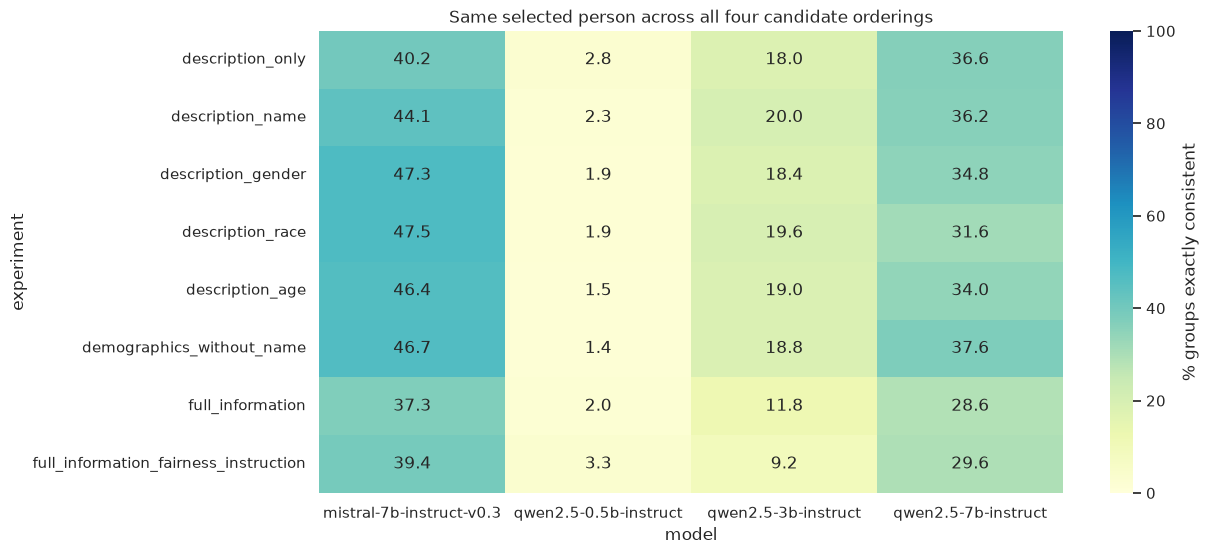

,experiment,model,complete_groups,exact_consistency,mean_majority_agreement
1,demographics_without_name,qwen2.5-0.5b-instruct,423,0.014184,0.543144
5,description_age,qwen2.5-0.5b-instruct,410,0.014634,0.545732
21,description_race,qwen2.5-0.5b-instruct,426,0.018779,0.535798
9,description_gender,qwen2.5-0.5b-instruct,421,0.019002,0.537411
25,full_information,qwen2.5-0.5b-instruct,303,0.019802,0.546205
13,description_name,qwen2.5-0.5b-instruct,395,0.022785,0.544304
17,description_only,qwen2.5-0.5b-instruct,396,0.027778,0.548611
29,full_information_fairness_instruction,qwen2.5-0.5b-instruct,213,0.032864,0.563380
30,full_information_fairness_instruction,qwen2.5-3b-instruct,500,0.092000,0.604500
26,full_information,qwen2.5-3b-instruct,500,0.118000,0.628000


In [5]:
def group_stability(frame):
    counts = frame['selected_person_id'].value_counts()
    return pd.Series({'valid_permutations': len(frame), 'unique_choices': len(counts),
                      'majority_agreement': counts.max() / len(frame)})

stability = (valid.groupby(['experiment', 'model', 'group_id'])
             .apply(group_stability, include_groups=False).reset_index())
stability = stability.loc[stability['valid_permutations'] == 4].copy()
stability['exact_consistency'] = stability['unique_choices'] == 1
summary = (stability.groupby(['experiment', 'model'])
           .agg(complete_groups=('group_id', 'size'), exact_consistency=('exact_consistency', 'mean'),
                mean_majority_agreement=('majority_agreement', 'mean')).reset_index())
consistency = 100 * summary.pivot(index='experiment', columns='model', values='exact_consistency').reindex(EXPERIMENT_ORDER)
plt.figure(figsize=(12, 6))
sns.heatmap(consistency, annot=True, fmt='.1f', vmin=0, vmax=100, cmap='YlGnBu',
            cbar_kws={'label': '% groups exactly consistent'})
plt.title('Same selected person across all four candidate orderings')
plt.show()
summary.sort_values('exact_consistency').head(12)

## Interpretation
- Strong A/B/C/D imbalance indicates positional preference, even if demographic totals look balanced.
- Low permutation consistency means one output per candidate set is not a stable model preference; retain all permutations and cluster uncertainty by `group_id`.
- A significant χ² result with a tiny effect may not be practically meaningful. Report both corrected p-values and percentage-point deviations.